# Dragon fruit classifier: transfer learning (project 1)

Before running anything: **Runtime > Change runtime type > T4 GPU**. Changing it later restarts the VM and wipes `/content`.

Upload `train_transfer.py` to `MyDrive/dragonfruit/` (next to `Cleaned.zip`), then run the cells top to bottom.

In [2]:
import torch
assert torch.cuda.is_available(), 'No GPU: Runtime > Change runtime type > T4 GPU, then re-run from the top'
print('GPU:', torch.cuda.get_device_name(0))

from google.colab import drive
drive.mount('/content/drive')

GPU: Tesla T4
Mounted at /content/drive


In [3]:
import os, shutil, subprocess
from PIL import Image

D = '/content/drive/MyDrive/dragon_fruit'
EXPECTED = 4160

# 1. outputs -> Drive, so a disconnect never costs a run
os.makedirs(f'{D}/outputs', exist_ok=True)
subprocess.run(['rm', '-rf', '/content/outputs'])
os.symlink(f'{D}/outputs', '/content/outputs')

# 2. training script
shutil.copy(f'{D}/train_transfer.py', '/content/train_transfer.py')

# 3. resized caches: restore from Drive if saved there, else build once and save
def unzip(zip_path):
    subprocess.run(['unzip', '-q', '-o', zip_path, '-d', '/content/'], check=True)

def build_cache(name, size, quality):
    dst = f'/content/{name}'
    if os.path.isdir(f'{dst}/train'):
        return
    saved = f'{D}/{name}.zip'
    if os.path.exists(saved):
        unzip(saved)
        return
    if not os.path.isdir('/content/Cleaned'):
        unzip(f'{D}/Cleaned.zip')
    src = '/content/Cleaned'
    for root, _, files in os.walk(src):
        for f in files:
            if not f.lower().endswith(('.jpg', '.jpeg', '.png')):
                continue
            out = root.replace(src, dst, 1)
            os.makedirs(out, exist_ok=True)
            im = Image.open(os.path.join(root, f)).convert('RGB')
            im.thumbnail((size, size))
            im.save(os.path.join(out, os.path.splitext(f)[0] + '.jpg'), quality=quality)
    # write to a temp name, then rename: an interrupted zip never looks complete
    shutil.make_archive(f'{D}/{name}_tmp', 'zip', root_dir='/content', base_dir=name)
    os.replace(f'{D}/{name}_tmp.zip', saved)

def count_images(path):
    return sum(f.lower().endswith('.jpg') for _, _, fs in os.walk(path) for f in fs)

for name, size, quality in [('small', 160, 92), ('med', 256, 95)]:
    build_cache(name, size, quality)
    n = count_images(f'/content/{name}')
    assert n == EXPECTED, f'/content/{name} has {n} images, expected {EXPECTED}: delete that folder and re-run this cell'
    print(f'{name}: {n} images')
print('outputs ->', os.readlink('/content/outputs'))

small: 4160 images
med: 4160 images
outputs -> /content/drive/MyDrive/dragon_fruit/outputs


In [ ]:
%cd /content
!python train_transfer.py --data_root /content/small --run_name tl_pre_128_s0 --weights imagenet --img_size 128 --seed 0

/content
Device: cuda
Classes: ['Bad fruit', 'Bad leaf', 'Good fruit', 'Good leaf']
Images: train 2809  val 674  test 677
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100% 44.7M/44.7M [00:00<00:00, 129MB/s]
ResNet18, weights=imagenet, params=11,178,564, img_size=128, lr=0.0001, seed=0
epoch 01/25 | train loss 0.465 acc 0.834 | val loss 0.284 acc 0.892 F1 0.860 | 6.7s  *best
epoch 02/25 | train loss 0.198 acc 0.928 | val loss 0.313 acc 0.892 F1 0.863 | 5.2s  *best
epoch 03/25 | train loss 0.130 acc 0.957 | val loss 0.333 acc 0.893 F1 0.886 | 5.7s  *best
epoch 04/25 | train loss 0.100 acc 0.965 | val loss 0.351 acc 0.895 F1 0.881 | 4.6s
epoch 05/25 | train loss 0.066 acc 0.975 | val loss 0.433 acc 0.893 F1 0.875 | 5.9s
epoch 06/25 | train loss 0.058 acc 0.975 | val loss 0.503 acc 0.884 F1 0.866 | 5.2s
epoch 07/25 | train loss 0.046 acc 0.981 | val loss 0.428 acc 0.886 F1 0.866 | 4.6s
epoch 08/25 | tra

In [4]:
import json, math, os, subprocess, time
import statistics as st

OUT = '/content/outputs'   # symlinked to Drive by the setup cell

# arm: (run prefix, data folder, img_size, weights, lr)
ARMS = {
    'A': ('tl_pre_128',       'small', 128, 'imagenet', '1e-4'),
    'C': ('tl_scratch_128',   'small', 128, 'none',     '1e-3'),
    'D': ('tl_pre_128_lr1e3', 'small', 128, 'imagenet', '1e-3'),
    'B': ('tl_pre_224',       'med',   224, 'imagenet', '1e-4'),
}

def run_arm(arm, seeds=range(5)):
    prefix, data, size, weights, lr = ARMS[arm]
    t0 = time.time()
    for seed in seeds:
        run = f'{prefix}_s{seed}'
        done = f'{OUT}/{run}/results.json'
        if os.path.exists(done):
            print(f'{run:24s} already done, skipping')
            continue
        cmd = ['python', 'train_transfer.py', '--data_root', f'/content/{data}',
               '--run_name', run, '--seed', str(seed), '--img_size', str(size),
               '--weights', weights, '--lr', lr]
        r = subprocess.run(cmd, capture_output=True, text=True, cwd='/content')
        if r.returncode:
            print(f'{run:24s} FAILED')
            print(r.stderr[-800:])
            return
        f1 = json.load(open(done))['test_macro_f1']
        print(f'{run:24s} ok  test macro-F1 {f1:.4f}  ({round(time.time() - t0)}s)')

In [ ]:
run_arm('A')
run_arm('C')
run_arm('D')

tl_pre_128_s0            already done, skipping
tl_pre_128_s1            ok  test macro-F1 0.8652  (151s)
tl_pre_128_s2            ok  test macro-F1 0.8595  (294s)
tl_pre_128_s3            ok  test macro-F1 0.8684  (440s)
tl_pre_128_s4            ok  test macro-F1 0.8618  (586s)
tl_scratch_128_s0        ok  test macro-F1 0.8168  (145s)
tl_scratch_128_s1        ok  test macro-F1 0.7915  (290s)
tl_scratch_128_s2        ok  test macro-F1 0.7176  (438s)
tl_scratch_128_s3        ok  test macro-F1 0.7953  (582s)
tl_scratch_128_s4        ok  test macro-F1 0.7607  (728s)
tl_pre_128_lr1e3_s0      ok  test macro-F1 0.8304  (146s)
tl_pre_128_lr1e3_s1      ok  test macro-F1 0.8306  (290s)
tl_pre_128_lr1e3_s2      ok  test macro-F1 0.8073  (435s)
tl_pre_128_lr1e3_s3      ok  test macro-F1 0.8159  (581s)
tl_pre_128_lr1e3_s4      ok  test macro-F1 0.8383  (729s)


In [7]:
BASELINE = dict(mean=0.7992, sd=0.0125, n=5)   # plain SimpleCNN @128, 5 seeds (project doc)

def f1s(prefix):
    out = []
    for s in range(5):
        p = f'{OUT}/{prefix}_s{s}/results.json'
        if os.path.exists(p):
            out.append(json.load(open(p))['test_macro_f1'])
    return out

stats = {'base': BASELINE}
print(f"{'arm':5s}{'n':>3s}{'mean':>9s}{'sd':>8s}   range")
for arm, cfg in ARMS.items():
    v = f1s(cfg[0])
    if not v:
        continue
    sd = st.stdev(v) if len(v) > 1 else float('nan')
    print(f"{arm:5s}{len(v):>3d}{st.mean(v):>9.4f}{sd:>8.4f}   {min(v):.3f}-{max(v):.3f}")
    if len(v) > 1:
        stats[arm] = dict(mean=st.mean(v), sd=sd, n=len(v))

def contrast(x, y, label):
    if x not in stats or y not in stats:
        return
    a, b = stats[x], stats[y]
    d = a['mean'] - b['mean']
    se = math.sqrt(a['sd'] ** 2 / a['n'] + b['sd'] ** 2 / b['n'])
    print(f'{x} - {y}: {d:+.4f}  ({d / se:+.1f} SE)   {label}')

print()
contrast('C', 'base', 'architecture only: ResNet18 from scratch vs SimpleCNN, same lr')
contrast('D', 'C',    'pretraining only: same architecture, same lr')
contrast('A', 'D',    'lr only: pretrained at 1e-4 vs 1e-3')
contrast('B', 'A',    'resolution: 224 vs 128, pretrained')

arm    n     mean      sd   range
A      5   0.8639  0.0034   0.859-0.868
C      5   0.7764  0.0385   0.718-0.817
D      5   0.8245  0.0126   0.807-0.838
B      5   0.8840  0.0126   0.865-0.895
E      5   0.7916  0.0081   0.784-0.802

C - base: -0.0228  (-1.3 SE)   architecture only: ResNet18 from scratch vs SimpleCNN, same lr
D - C: +0.0482  (+2.7 SE)   pretraining only: same architecture, same lr
A - D: +0.0394  (+6.8 SE)   lr only: pretrained at 1e-4 vs 1e-3
B - A: +0.0201  (+3.4 SE)   resolution: 224 vs 128, pretrained


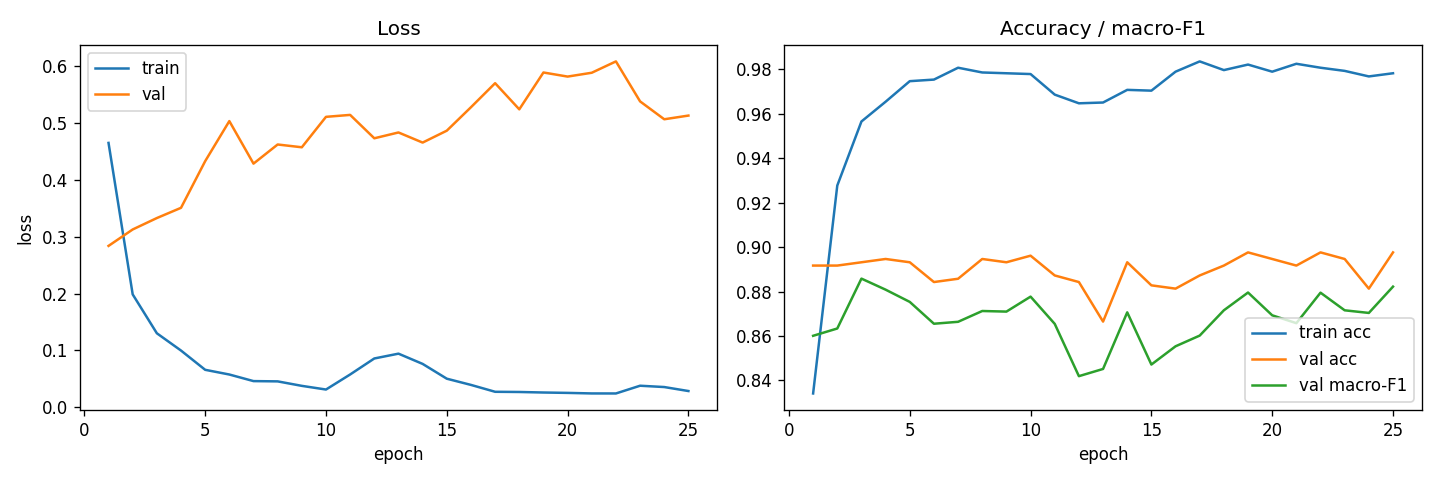

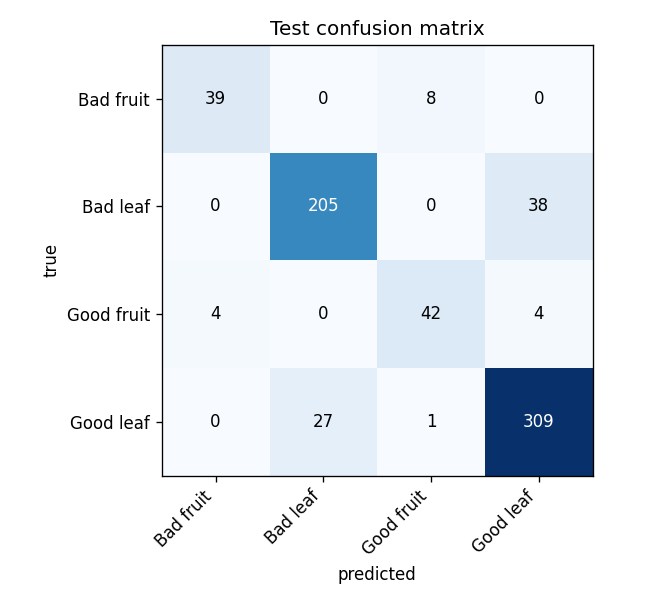

In [ ]:
from IPython.display import Image, display

def show(run):
    for f in ['curves.png', 'confusion_matrix.png']:
        display(Image(f'{OUT}/{run}/{f}'))

show('tl_pre_128_s0')

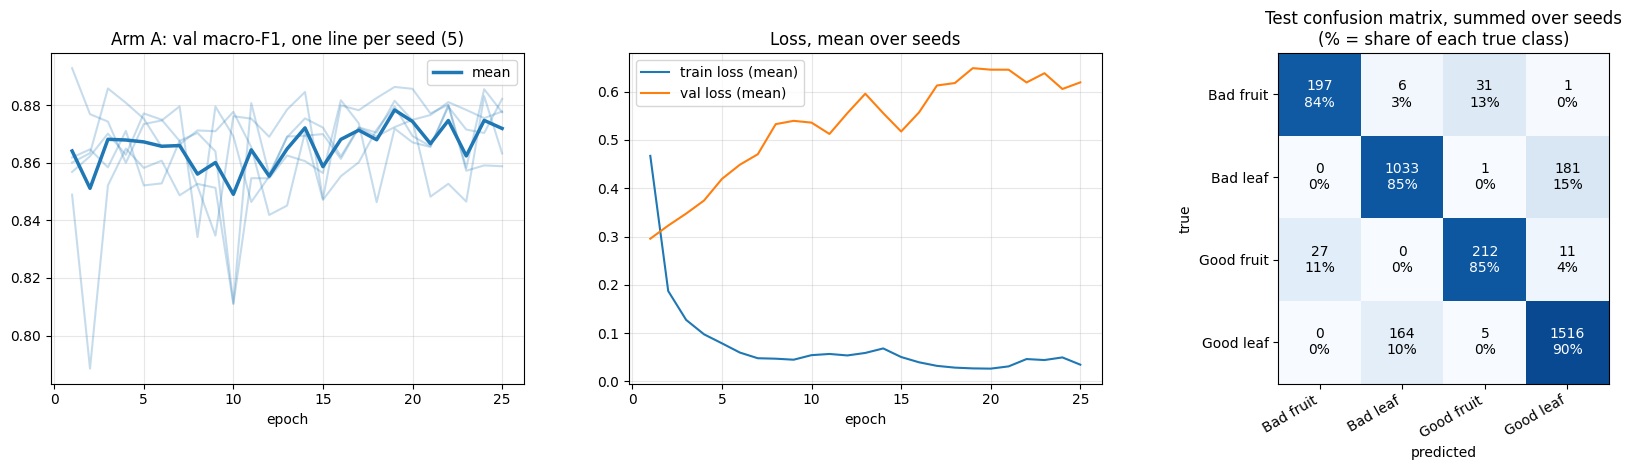

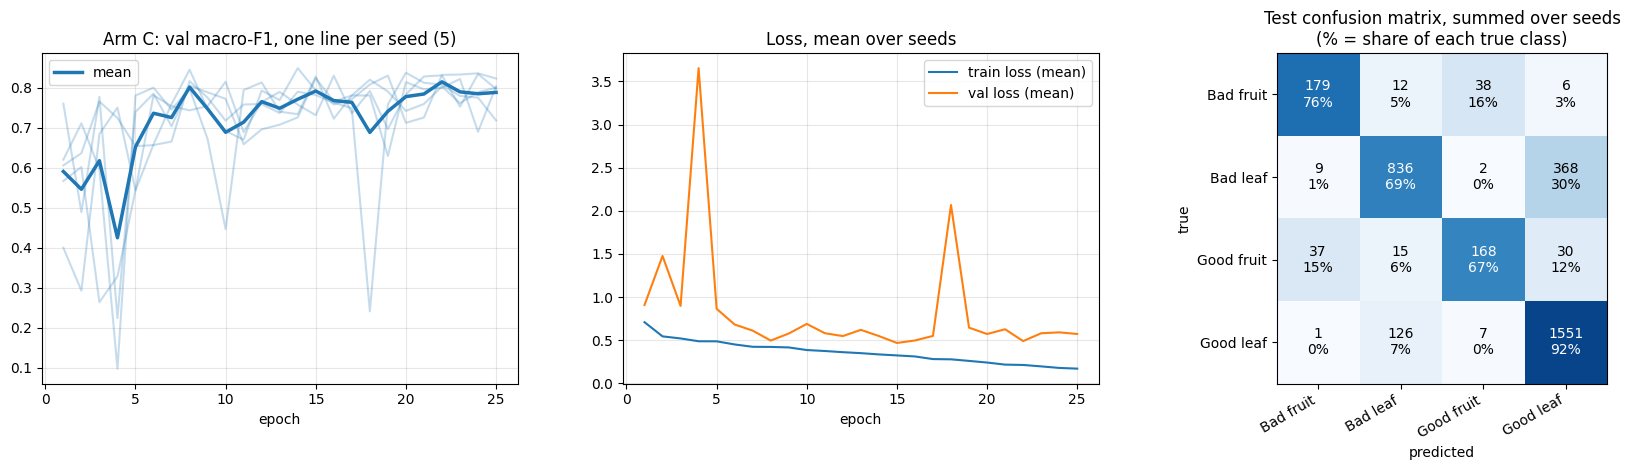

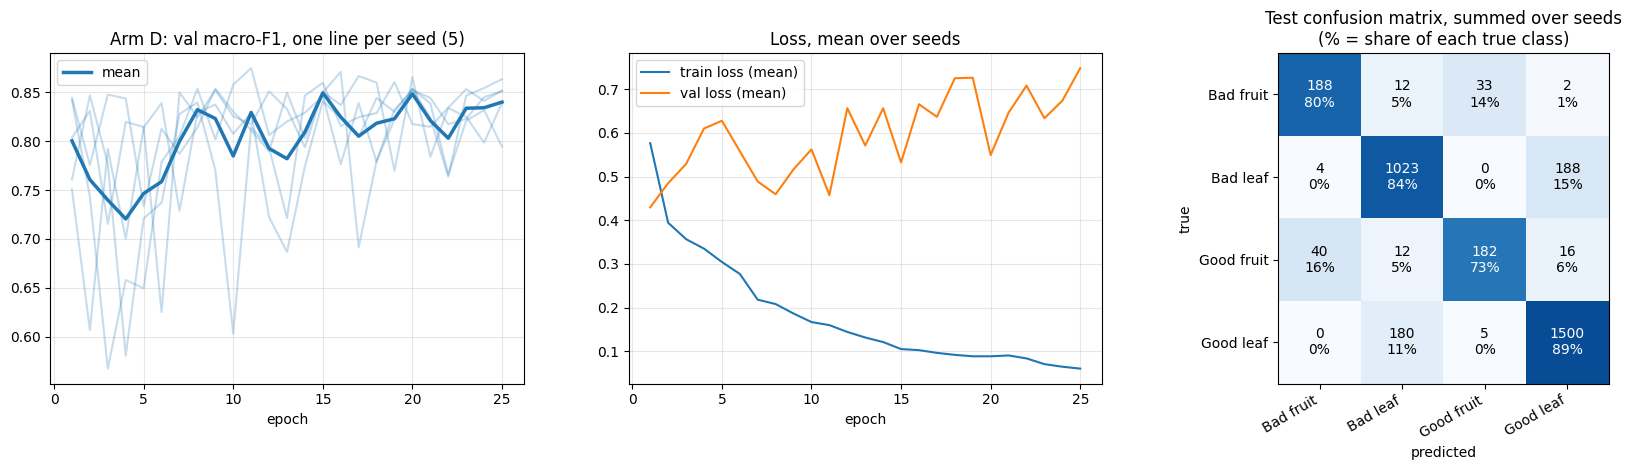

arm B: no finished runs


In [ ]:
import re
import numpy as np
import matplotlib.pyplot as plt

CLASSES = ['Bad fruit', 'Bad leaf', 'Good fruit', 'Good leaf']

def load_cm(run):
    # the matrix is printed at the end of test_report.txt; 4 classes -> 16 integers
    txt = open(f'{OUT}/{run}/test_report.txt').read()
    tail = txt.split('confusion matrix (rows true, cols predicted):')[1]
    return np.array([int(x) for x in re.findall(r'\d+', tail)]).reshape(4, 4)

def arm_figure(arm):
    prefix = ARMS[arm][0]
    runs = [f'{prefix}_s{s}' for s in range(5)
            if os.path.exists(f'{OUT}/{prefix}_s{s}/results.json')]
    if not runs:
        print(f'arm {arm}: no finished runs')
        return
    hist = [json.load(open(f'{OUT}/{r}/history.json')) for r in runs]
    cm = sum(load_cm(r) for r in runs)
    rows = cm / cm.sum(1, keepdims=True)
    ep = np.arange(1, len(hist[0]['val_f1']) + 1)

    fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
    for h in hist:
        ax[0].plot(ep, h['val_f1'], color='tab:blue', alpha=0.25)
    ax[0].plot(ep, np.mean([h['val_f1'] for h in hist], 0), color='tab:blue', lw=2.5, label='mean')
    ax[0].set(title=f'Arm {arm}: val macro-F1, one line per seed ({len(runs)})', xlabel='epoch')
    ax[0].legend(); ax[0].grid(alpha=0.3)

    ax[1].plot(ep, np.mean([h['train_loss'] for h in hist], 0), label='train loss (mean)')
    ax[1].plot(ep, np.mean([h['val_loss'] for h in hist], 0), label='val loss (mean)')
    ax[1].set(title='Loss, mean over seeds', xlabel='epoch')
    ax[1].legend(); ax[1].grid(alpha=0.3)

    ax[2].imshow(rows, cmap='Blues', vmin=0, vmax=1)
    for i in range(4):
        for j in range(4):
            ax[2].text(j, i, f'{cm[i, j]}\n{rows[i, j]:.0%}', ha='center', va='center',
                       color='white' if rows[i, j] > 0.5 else 'black')
    ax[2].set_xticks(range(4)); ax[2].set_yticks(range(4))
    ax[2].set_xticklabels(CLASSES, rotation=30, ha='right'); ax[2].set_yticklabels(CLASSES)
    ax[2].set(title='Test confusion matrix, summed over seeds\n(% = share of each true class)',
              xlabel='predicted', ylabel='true')

    fig.tight_layout()
    os.makedirs(f'{OUT}/_summary', exist_ok=True)
    fig.savefig(f'{OUT}/_summary/arm_{arm}.png', dpi=130)
    plt.show()

for a in ARMS:
    arm_figure(a)

In [5]:
ARMS['E'] = ('tl_scratch_128_lr1e4', 'small', 128, 'none', '1e-4')
run_arm('E')
run_arm('B')

tl_scratch_128_lr1e4_s0  ok  test macro-F1 0.7848  (172s)
tl_scratch_128_lr1e4_s1  ok  test macro-F1 0.7841  (320s)
tl_scratch_128_lr1e4_s2  ok  test macro-F1 0.8025  (467s)
tl_scratch_128_lr1e4_s3  ok  test macro-F1 0.7976  (617s)
tl_scratch_128_lr1e4_s4  ok  test macro-F1 0.7891  (769s)
tl_pre_224_s0            ok  test macro-F1 0.8896  (322s)
tl_pre_224_s1            ok  test macro-F1 0.8929  (645s)
tl_pre_224_s2            ok  test macro-F1 0.8948  (962s)
tl_pre_224_s3            ok  test macro-F1 0.8781  (1282s)
tl_pre_224_s4            ok  test macro-F1 0.8647  (1611s)


In [8]:
contrast('A', 'E', 'pretraining only at lr 1e-4')
contrast('E', 'C', 'scratch lr: 1e-4 vs 1e-3')

for arm, cfg in ARMS.items():
    be = [json.load(open(f'{OUT}/{cfg[0]}_s{s}/results.json'))['best_epoch']
          for s in range(5) if os.path.exists(f'{OUT}/{cfg[0]}_s{s}/results.json')]
    print(arm, 'best epochs:', be)

A - E: +0.0723  (+18.4 SE)   pretraining only at lr 1e-4
E - C: +0.0153  (+0.9 SE)   scratch lr: 1e-4 vs 1e-3
A best epochs: [3, 19, 1, 24, 16]
C best epochs: [20, 15, 24, 14, 15]
D best epochs: [11, 19, 16, 17, 20]
B best epochs: [17, 16, 1, 8, 6]
E best epochs: [13, 12, 3, 12, 24]


In [ ]:
OUT = '/content/drive/MyDrive/dragon_fruit/outputs'

In [9]:
ARMS['E'] = ('tl_scratch_128_lr1e4', 'small', 128, 'none', '1e-4')
run_arm('E')
run_arm('B')

tl_scratch_128_lr1e4_s0  already done, skipping
tl_scratch_128_lr1e4_s1  already done, skipping
tl_scratch_128_lr1e4_s2  already done, skipping
tl_scratch_128_lr1e4_s3  already done, skipping
tl_scratch_128_lr1e4_s4  already done, skipping
tl_pre_224_s0            already done, skipping
tl_pre_224_s1            already done, skipping
tl_pre_224_s2            already done, skipping
tl_pre_224_s3            already done, skipping
tl_pre_224_s4            already done, skipping


In [10]:
!unzip -q -o "/content/drive/MyDrive/dragon_fruit/Cleaned.zip" "*manifest.csv" "*repair_summary.json" -d /content/meta
!for f in $(find /content/meta -type f); do echo "== $f"; head -c 1200 "$f"; echo; done

== /content/meta/Cleaned/manifest.csv
sha256,class_name,new_split,source_sample_id,source_original_split,source_path,destination_relative,representative_reason,n_original_copies,all_original_sample_ids
1608e39ffad76cbf66a8f27fd7f8bd4b69e48665d8ea8c237b5a39ce873ad344,Bad fruit,train,train/Bad fruit/BGR (1712).jpg,train,/kaggle/input/datasets/ohmahler91/dragon-fruit-and-leaf-dataset-from-bangladesh/Cleaned/train/Bad fruit/BGR (1712).jpg,train/Bad fruit/1608e39ffad7__BGR (1712).jpg,preserved_original_split,1,train/Bad fruit/BGR (1712).jpg
edfac5e2a08b207b0edcdff2221c18d18d6d0ea33529b30ad3852fe6a17b3d6e,Bad fruit,train,train/Bad fruit/BGR (1975).jpg,train,/kaggle/input/datasets/ohmahler91/dragon-fruit-and-leaf-dataset-from-bangladesh/Cleaned/train/Bad fruit/BGR (1975).jpg,train/Bad fruit/edfac5e2a08b__BGR (1975).jpg,preserved_original_split,1,train/Bad fruit/BGR (1975).jpg
3504d1a47633fb54dcef820e7bb7839cd7349d94d3f8798c7383e9c9ea61aa5d,Bad fruit,train,train/Bad fruit/BGR (1976).jpg,train,

                               n  median    p99    max  emb>=.95  emb>=.98  hash<=6  hash<=10
train -> other train        2809   0.913  1.000  1.000     33.1%     30.9%    79.7%     90.0%
val -> train                 674   0.903  1.000  1.000     30.6%     27.4%    76.0%     89.2%
test -> train                677   0.905  1.000  1.000     28.8%     26.7%    77.8%     90.1%

val/test images with a >=0.95 train neighbour: 401; neighbour has the same label in 89% of them


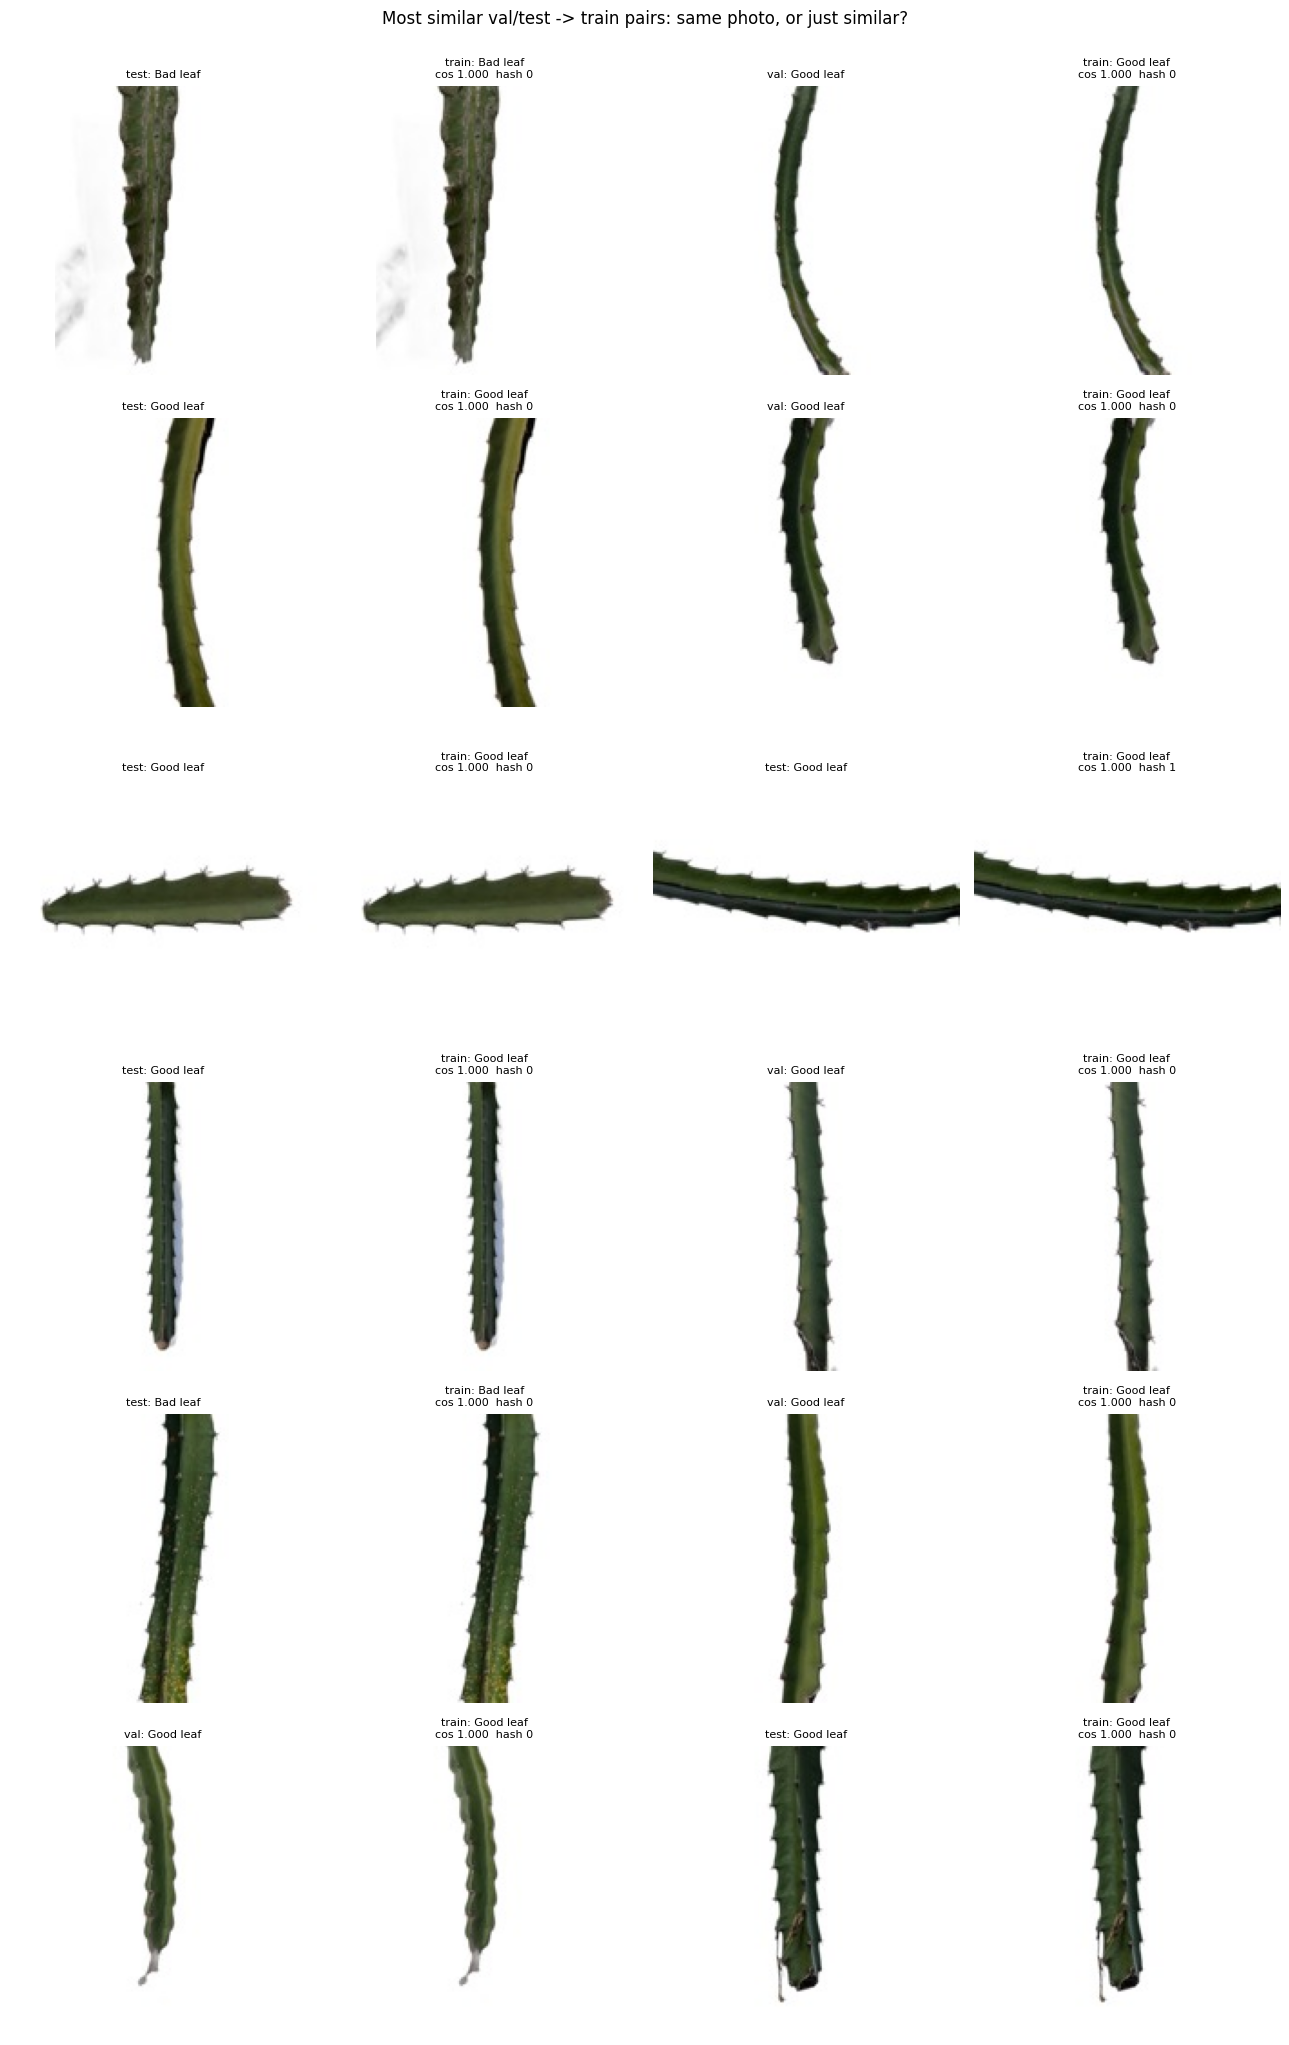


How to read it:
  cross-split rows ~ train -> other train row, both high  -> duplicates are spread across splits (leakage likely)
  cross-split rows far below the train row                -> duplicates were kept inside one split (looks clean)
  all rows low                                            -> no near-duplicates at these thresholds
  The picture decides: are the two images the same photo/object, or merely similar-looking leaves?


In [11]:
import csv, os
import numpy as np
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import datasets, models, transforms

ROOT = '/content/small'
SAVE = f'{OUT}/_summary'
N_PAIRS = 12                      # pairs shown in the picture (even number)
dev = 'cuda' if torch.cuda.is_available() else 'cpu'

mean, std = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
tfm = transforms.Compose([transforms.Resize((128, 128)), transforms.ToTensor(),
                          transforms.Normalize(mean, std)])
ds = {s: datasets.ImageFolder(f'{ROOT}/{s}', tfm) for s in ['train', 'val', 'test']}
paths = {s: [p for p, _ in ds[s].samples] for s in ds}
labels = {s: np.array(ds[s].targets) for s in ds}
classes = ds['train'].classes

# --- signal 1: ImageNet ResNet18 features (robust to crops, brightness, re-shoots) ---
net = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
net.fc = nn.Identity()
net = net.eval().to(dev)

def embed(d):
    out = []
    with torch.no_grad():
        for x, _ in torch.utils.data.DataLoader(d, batch_size=64, num_workers=2):
            f = net(x.to(dev)).cpu().numpy()
            out.append(f / np.linalg.norm(f, axis=1, keepdims=True))
    return np.concatenate(out)

emb = {s: embed(ds[s]) for s in ds}

# --- signal 2: 64-bit difference hash, compared under all 8 flips/rotations ---
T = Image.Transpose
D8 = [None, T.ROTATE_90, T.ROTATE_180, T.ROTATE_270,
      T.FLIP_LEFT_RIGHT, T.FLIP_TOP_BOTTOM, T.TRANSPOSE, T.TRANSVERSE]

def dhash(im):
    g = np.asarray(im.convert('L').resize((9, 8), Image.Resampling.BILINEAR), dtype=np.float32)
    return np.where((g[:, 1:] > g[:, :-1]).ravel(), 1.0, -1.0)

def hashes(split, all8):
    out = []
    for p in paths[split]:
        im = Image.open(p).convert('RGB')
        if all8:
            out.append(np.stack([dhash(im if t is None else im.transpose(t)) for t in D8]))
        else:
            out.append(dhash(im))
    return np.array(out)

H_tr = hashes('train', True)                                  # (n, 8, 64)
H = {'train': H_tr[:, 0, :], 'val': hashes('val', False), 'test': hashes('test', False)}

def min_hamming(Q, self_ref=False):
    best = np.full((len(Q), len(H_tr)), 64.0)
    for t in range(8):
        best = np.minimum(best, (64 - Q @ H_tr[:, t, :].T) / 2)
    if self_ref:
        np.fill_diagonal(best, 64.0)                          # ignore an image matching itself
    return best.min(1)

# --- nearest train neighbour for every image ---
nn_sim, nn_idx, ham = {}, {}, {}
for s in ['val', 'test']:
    S = emb[s] @ emb['train'].T
    nn_sim[s], nn_idx[s], ham[s] = S.max(1), S.argmax(1), min_hamming(H[s])
S = emb['train'] @ emb['train'].T
np.fill_diagonal(S, -1)                                       # nearest OTHER train image
nn_sim['train'], nn_idx['train'], ham['train'] = S.max(1), S.argmax(1), min_hamming(H['train'], True)

print(f"{'':26s}{'n':>6s}{'median':>8s}{'p99':>7s}{'max':>7s}{'emb>=.95':>10s}{'emb>=.98':>10s}{'hash<=6':>9s}{'hash<=10':>10s}")
for s, name in [('train', 'train -> other train'), ('val', 'val -> train'), ('test', 'test -> train')]:
    x, h = nn_sim[s], ham[s]
    print(f"{name:26s}{len(x):>6d}{np.median(x):>8.3f}{np.percentile(x, 99):>7.3f}{x.max():>7.3f}"
          f"{(x >= .95).mean():>10.1%}{(x >= .98).mean():>10.1%}{(h <= 6).mean():>9.1%}{(h <= 10).mean():>10.1%}")

# --- most similar val/test -> train pairs: table + picture ---
rows = [(s, i, nn_sim[s][i], nn_idx[s][i], ham[s][i]) for s in ['val', 'test'] for i in range(len(paths[s]))]
rows.sort(key=lambda r: -r[2])
os.makedirs(SAVE, exist_ok=True)
with open(f'{SAVE}/near_duplicates_top200.csv', 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['split', 'query_path', 'train_path', 'emb_cosine', 'min_hash_dist', 'query_label', 'train_label'])
    for s, i, sim, j, hd in rows[:200]:
        w.writerow([s, paths[s][i], paths['train'][j], f'{sim:.4f}', int(hd),
                    classes[labels[s][i]], classes[labels['train'][j]]])
agree = np.mean([labels[s][i] == labels['train'][j] for s, i, sim, j, hd in rows if sim >= 0.95] or [np.nan])
print(f"\nval/test images with a >=0.95 train neighbour: {sum(r[2] >= .95 for r in rows)}; "
      f"neighbour has the same label in {agree:.0%} of them")

fig, ax = plt.subplots(N_PAIRS // 2, 4, figsize=(13, 3.4 * (N_PAIRS // 2)))
for k, (s, i, sim, j, hd) in enumerate(rows[:N_PAIRS]):
    r, c = divmod(k, 2)
    for m, (p, ttl) in enumerate([(paths[s][i], f'{s}: {classes[labels[s][i]]}'),
                                   (paths['train'][j], f"train: {classes[labels['train'][j]]}\ncos {sim:.3f}  hash {int(hd)}")]):
        a = ax[r, 2 * c + m]
        a.imshow(Image.open(p)); a.axis('off'); a.set_title(ttl, fontsize=8)
fig.suptitle('Most similar val/test -> train pairs: same photo, or just similar?', y=1.0)
fig.tight_layout()
fig.savefig(f'{SAVE}/near_dup_pairs.png', dpi=110)
plt.show()

print('''
How to read it:
  cross-split rows ~ train -> other train row, both high  -> duplicates are spread across splits (leakage likely)
  cross-split rows far below the train row                -> duplicates were kept inside one split (looks clean)
  all rows low                                            -> no near-duplicates at these thresholds
  The picture decides: are the two images the same photo/object, or merely similar-looking leaves?''')

In [12]:
import shutil, sys
from sklearn.metrics import f1_score
from torch.utils.data import DataLoader

BASE_OUT = '/content/drive/MyDrive/dragonfruit/outputs'    # SimpleCNN baseline runs live in the older folder
TAUS = [0.95, 0.98, 0.995]                                 # cosine cutoffs for "has a near-duplicate twin in train"

shutil.copy(f'{D}/train_baseline.py', '/content/train_baseline.py')
sys.path.insert(0, '/content')
from train_baseline import SimpleCNN

def loader(data, size):
    t = transforms.Compose([transforms.Resize((size, size)), transforms.ToTensor(),
                            transforms.Normalize(mean, std)])
    d = datasets.ImageFolder(f'/content/{data}/test', t)
    assert (np.array(d.targets) == labels['test']).all(), 'test image order differs from the check cell'
    return DataLoader(d, batch_size=64, num_workers=2)

def predict(model, dl):
    model = model.to(dev).eval()
    out = []
    with torch.no_grad():
        for x, _ in dl:
            out.append(model(x.to(dev)).argmax(1).cpu())
    return torch.cat(out).numpy()

def resnet(path):
    m = models.resnet18(weights=None)
    m.fc = nn.Linear(512, 4)
    m.load_state_dict(torch.load(path, map_location=dev))
    return m

def simple(path):
    m = SimpleCNN(4, False, 0.0)
    m.load_state_dict(torch.load(path, map_location=dev))
    return m

# arm: (run prefix, folder holding the runs, checkpoint file, model builder, data folder, img_size)
EVAL = {
    'base': ('run_plain',            BASE_OUT, 'best_model.pt', simple, 'small', 128),
    'E':    ('tl_scratch_128_lr1e4', OUT,      'best.pt',       resnet, 'small', 128),
    'C':    ('tl_scratch_128',       OUT,      'best.pt',       resnet, 'small', 128),
    'D':    ('tl_pre_128_lr1e3',     OUT,      'best.pt',       resnet, 'small', 128),
    'A':    ('tl_pre_128',           OUT,      'best.pt',       resnet, 'small', 128),
    'B':    ('tl_pre_224',           OUT,      'best.pt',       resnet, 'med',   224),
}

preds = {}
for arm, (prefix, root, ckpt, build, data, size) in EVAL.items():
    dl = loader(data, size)
    preds[arm] = []
    for s in range(5):
        p = f'{root}/{prefix}_s{s}/{ckpt}'
        if os.path.exists(p):
            preds[arm].append(predict(build(p), dl))
    print(f'{arm}: {len(preds[arm])} checkpoints scored')

y, sim = labels['test'], nn_sim['test']
everyone = np.ones(len(y), bool)

def f1(p, mask):
    if mask.sum() == 0:                       # a cutoff can leave a subset empty
        return float('nan')
    return f1_score(y[mask], p[mask], average='macro', zero_division=0)

for tau in TAUS:
    free = sim < tau
    print(f'\ntau = {tau}: {free.sum()} of {len(y)} test images have no train twin  '
          f'(per class: {dict(zip(classes, np.bincount(y[free], minlength=4).tolist()))})')
    print(f"{'arm':6s}{'all test':>10s}{'twin-free':>11s}{'sd':>8s}{'with twin':>11s}{'free - all':>12s}")
    for arm, P in preds.items():
        if not P:
            continue
        a = [f1(p, everyone) for p in P]
        fr = [f1(p, free) for p in P]
        tw = [f1(p, ~free) for p in P]
        print(f'{arm:6s}{np.mean(a):>10.4f}{np.mean(fr):>11.4f}{np.std(fr, ddof=1) if len(fr) > 1 else float("nan"):>8.4f}'
              f'{np.mean(tw):>11.4f}{np.mean(fr) - np.mean(a):>+12.4f}')

base: 5 checkpoints scored
E: 5 checkpoints scored
C: 5 checkpoints scored
D: 5 checkpoints scored
A: 5 checkpoints scored
B: 5 checkpoints scored

tau = 0.95: 482 of 677 test images have no train twin  (per class: {'Bad fruit': 46, 'Bad leaf': 161, 'Good fruit': 46, 'Good leaf': 229})
arm     all test  twin-free      sd  with twin  free - all
base      0.7992     0.7953  0.0143     0.8717     -0.0039
E         0.7916     0.7793  0.0153     0.7321     -0.0123
C         0.7764     0.7754  0.0357     0.7699     -0.0010
D         0.8245     0.8237  0.0096     0.7160     -0.0008
A         0.8639     0.8643  0.0041     0.7671     +0.0003
B         0.8840     0.8916  0.0123     0.7925     +0.0076

tau = 0.98: 496 of 677 test images have no train twin  (per class: {'Bad fruit': 46, 'Bad leaf': 167, 'Good fruit': 47, 'Good leaf': 236})
arm     all test  twin-free      sd  with twin  free - all
base      0.7992     0.7984  0.0140     0.8502     -0.0008
E         0.7916     0.7825  0.0133     0.

In [13]:
TAU = 0.98
twin = sim >= TAU                                     # test images with a near-identical train twin
twin_label = labels['train'][nn_idx['test']]          # label of each test image's nearest train image
same, diff = twin & (twin_label == y), twin & (twin_label != y)
leaf = np.isin(y, [classes.index('Bad leaf'), classes.index('Good leaf')])

print(f'test images with a train twin (cos >= {TAU}): {twin.sum()}  ->  same label {same.sum()}, different label {diff.sum()}')
pairs = {}
for a in range(4):
    for b in range(4):
        n = int((twin & (y == a) & (twin_label == b) & (a != b)).sum())
        if n:
            pairs[f'{classes[a]} -> {classes[b]}'] = n
print('different-label twins (test label -> twin label):', pairs)

def acc(P, m):
    return np.mean([np.mean(p[m] == y[m]) for p in P]) if m.sum() else float('nan')

print(f"\n{'arm':6s}{'leaf, no twin':>15s}{'twin, same label':>18s}{'twin, other label':>19s}{'follows twin label':>20s}")
for arm, P in preds.items():
    if not P:
        continue
    follow = np.mean([np.mean(p[diff] == twin_label[diff]) for p in P]) if diff.sum() else float('nan')
    print(f'{arm:6s}{acc(P, leaf & ~twin):>15.3f}{acc(P, same):>18.3f}{acc(P, diff):>19.3f}{follow:>20.3f}')

# gallery: test images whose near-identical train twin carries a different label
idx = np.where(diff)[0]
idx = idx[np.argsort(-sim[idx])][:12]
if len(idx):
    rows_ = (len(idx) + 1) // 2
    fig, ax = plt.subplots(rows_, 4, figsize=(13, 3.4 * rows_), squeeze=False)
    for a_ in ax.ravel():
        a_.axis('off')
    for k, i in enumerate(idx):
        r, c = divmod(k, 2)
        j = nn_idx['test'][i]
        lab_t, lab_r = classes[y[i]], classes[labels['train'][j]]
        for m, (p, ttl) in enumerate([(paths['test'][i], f'test: {lab_t}'),
                                       (paths['train'][j], f'train: {lab_r}\ncos {sim[i]:.3f}')]):
            ax[r, 2 * c + m].imshow(Image.open(p))
            ax[r, 2 * c + m].set_title(ttl, fontsize=8)
    fig.suptitle('Test images whose near-identical train twin has a DIFFERENT label', y=1.0)
    fig.tight_layout()
    fig.savefig(f'{SAVE}/label_conflict_pairs.png', dpi=110)
    plt.show()

test images with a train twin (cos >= 0.98): 181  ->  same label 161, different label 20
different-label twins (test label -> twin label): {'Bad leaf -> Good leaf': 6, 'Good fruit -> Bad fruit': 1, 'Good fruit -> Good leaf': 1, 'Good leaf -> Bad leaf': 11, 'Good leaf -> Good fruit': 1}

arm     leaf, no twin  twin, same label  twin, other label  follows twin label
base            0.863             0.904              0.420               0.580
E               0.812             0.976              0.050               0.950
C               0.826             0.868              0.350               0.640
D               0.862             0.983              0.050               0.950
A               0.873             0.985              0.070               0.930
B               0.923             0.994              0.050               0.950


In [14]:
for name, mask in [('all test', np.ones(len(y), bool)), ('twin-free (cos < 0.98)', sim < 0.98)]:
    print(f'\n{name}: per-class F1, mean over 5 seeds')
    print(f"{'arm':6s}" + ''.join(f'{c:>12s}' for c in classes) + f"{'macro':>9s}")
    for arm, P in preds.items():
        if not P:
            continue
        f = np.mean([f1_score(y[mask], p[mask], average=None, labels=range(4), zero_division=0) for p in P], axis=0)
        print(f'{arm:6s}' + ''.join(f'{v:>12.3f}' for v in f) + f'{f.mean():>9.4f}')


all test: per-class F1, mean over 5 seeds
arm      Bad fruit    Bad leaf  Good fruit   Good leaf    macro
base         0.772       0.816       0.725       0.884   0.7992
E            0.787       0.777       0.744       0.858   0.7916
C            0.777       0.756       0.719       0.853   0.7764
D            0.805       0.838       0.771       0.884   0.8245
A            0.858       0.854       0.850       0.893   0.8639
B            0.866       0.898       0.849       0.923   0.8840

twin-free (cos < 0.98): per-class F1, mean over 5 seeds
arm      Bad fruit    Bad leaf  Good fruit   Good leaf    macro
base         0.767       0.811       0.726       0.889   0.7984
E            0.792       0.730       0.764       0.844   0.7825
C            0.777       0.754       0.731       0.855   0.7793
D            0.810       0.818       0.792       0.880   0.8249
A            0.865       0.842       0.871       0.891   0.8670
B            0.870       0.902       0.869       0.932   0.8933
